# Task 4 — Inverse heat-source reconstruction
**Numerical Solution and PDE-Constrained Optimization of the Two-Dimensional Heat Equation**

This notebook uses the **saved Task 3 dataset** (`phase3_observation_data.npz`), not newly generated temperatures. The true coefficients are reserved exclusively for evaluation.

**Goals:** derive a finite-dimensional inverse problem; solve ordinary and Tikhonov-regularized least squares; independently confirm the optimization with BFGS; reconstruct the spatial source; analyze residuals and regularization sensitivity.

## 1. Mathematical derivation
The forward solver and observation operator give

$$\mathbf d=\mathbf A\boldsymbol\theta+\boldsymbol\varepsilon,\qquad
\mathbf A\in\mathbb R^{m\times p},\quad m=48,\quad p=3.$$

Given noisy observations $\mathbf d$, estimate the source coefficients by minimizing

$$J_\lambda(\boldsymbol\theta)=\frac{1}{2m}\|\mathbf A\boldsymbol\theta-\mathbf d\|_2^2+\frac{\lambda}{2}\|\boldsymbol\theta\|_2^2.$$

Its gradient and Hessian are

$$\nabla J_\lambda(\boldsymbol\theta)=\frac1m\mathbf A^\mathsf T(\mathbf A\boldsymbol\theta-\mathbf d)+\lambda\boldsymbol\theta,$$

$$\nabla^2 J_\lambda=\frac1m\mathbf A^\mathsf T\mathbf A+\lambda\mathbf I.$$

At the minimizer,

$$\boxed{(\mathbf A^\mathsf T\mathbf A+m\lambda\mathbf I)\widehat{\boldsymbol\theta}=\mathbf A^\mathsf T\mathbf d.}$$

For $\lambda=0$ this is least squares (solved with `lstsq` rather than explicitly forming the inverse). For $\lambda>0$ the normal-equation matrix is symmetric positive definite. **Important:** the source is only guaranteed identifiable in the selected three-dimensional basis; the continuous unrestricted inverse problem may be much harder.

## 2. Load the *original* Task 3 dataset
Upload `phase3_observation_data.npz` to Colab when prompted, or place it next to the notebook locally.

In [37]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

path = Path('phase3_observation_data.npz')
if not path.exists():
    try:
        from google.colab import files
        print('Upload the original Task 3 NPZ dataset:')
        files.upload()
    except ImportError:
        raise FileNotFoundError('Place phase3_observation_data.npz beside this notebook.')
if not path.exists():
    raise FileNotFoundError('Task 3 dataset was not uploaded.')
with np.load(path) as z:
    A=z['A'].copy(); d=z['d_noisy'].copy()
    d_clean=z['d_clean'].copy(); basis=z['basis'].copy()
    theta_true=z['theta_true'].copy(); source_true=z['source_true'].copy()
    x=z['x'].copy(); y=z['y'].copy()
m,p=A.shape
assert p==len(theta_true)==len(basis)
assert np.linalg.matrix_rank(A)==p
assert np.allclose(A@theta_true,d_clean,atol=1e-13)
print('A:',A.shape,'observations:',d.shape,'rank:',np.linalg.matrix_rank(A))
print('Condition number:',np.linalg.cond(A))

A: (48, 3) observations: (48,) rank: 3
Condition number: 1.8063590725990064


## 3. Implement least squares and Tikhonov regularization
The value $\lambda=10^{-7}$ is an **illustrative** regularization strength chosen to compare with the unregularized fit. It is not chosen by looking at ground-truth reconstruction error in a real application.

In [38]:
def reconstruct(A, d, lam=0.0):
    if lam<0: raise ValueError('lam must be nonnegative')
    m,p=A.shape
    if lam==0:
        return np.linalg.lstsq(A,d,rcond=None)[0]
    return np.linalg.solve(A.T@A+m*lam*np.eye(p),A.T@d)

lam = 1e-7
theta_ls = reconstruct(A,d,0)
theta_ridge = reconstruct(A,d,lam)
print('Unregularized:',theta_ls)
print('Regularized:',theta_ridge)
print('Residual RMSE (LS):',np.linalg.norm(A@theta_ls-d)/np.sqrt(m))
print('Residual RMSE (ridge):',np.linalg.norm(A@theta_ridge-d)/np.sqrt(m))

Unregularized: [1.20393747 0.85309028 1.06273787]
Regularized: [1.20257698 0.85270439 1.06068126]
Residual RMSE (LS): 0.0003775762198214521
Residual RMSE (ridge): 0.0003781249219895801


## 4. Validate gradient and compare to BFGS
The regularized quadratic is solved independently with a gradient-based numerical optimizer. Because this is a simple full-rank problem, direct least squares remains the preferred numerical baseline.

In [39]:
def objective(theta):
    r=A@theta-d
    return r@r/(2*m)+lam*(theta@theta)/2

def gradient(theta):
    return A.T@(A@theta-d)/m+lam*theta

check=np.array([0.7,0.6,0.5]); eps=1e-6
numerical_grad=np.array([(objective(check+eps*np.eye(p)[i])-objective(check-eps*np.eye(p)[i]))/(2*eps) for i in range(p)])
assert np.allclose(gradient(check),numerical_grad,atol=1e-10)
sol=minimize(objective,np.zeros(p),jac=gradient,method='BFGS',options={'gtol':1e-12,'maxiter':1000})
assert np.allclose(sol.x,theta_ridge,atol=1e-6)
print('BFGS:',sol.x,'success:',sol.success,'iterations:',sol.nit)

BFGS: [1.20257699 0.8527044  1.06068125] success: True iterations: 28


## 5. Evaluate against the held-out true coefficients
The truth is used **only after fitting**. We evaluate coefficient error, source-field error, and temperature residual separately.

In [40]:
def source_from_theta(theta,basis):
    return np.einsum('r,rij->ij',theta,basis)

source_ls=source_from_theta(theta_ls,basis)
source_ridge=source_from_theta(theta_ridge,basis)

def relative_error(estimate,truth):
    return np.linalg.norm(estimate-truth)/np.linalg.norm(truth)

for name,theta,field in [('Least squares',theta_ls,source_ls),('Ridge',theta_ridge,source_ridge)]:
    print(f'{name}: coefficient error={relative_error(theta,theta_true):.4%}, '
          f'source error={relative_error(field,source_true):.4%}, '
          f'data RMSE={np.linalg.norm(A@theta-d)/np.sqrt(m):.7f}')
assert relative_error(source_ridge,source_true)<0.03  # synthetic low-noise regression check

Least squares: coefficient error=0.7574%, source error=0.6882%, data RMSE=0.0003776
Ridge: coefficient error=0.6262%, source error=0.5684%, data RMSE=0.0003781


## 6. Plot the recovered source field and sensor predictions

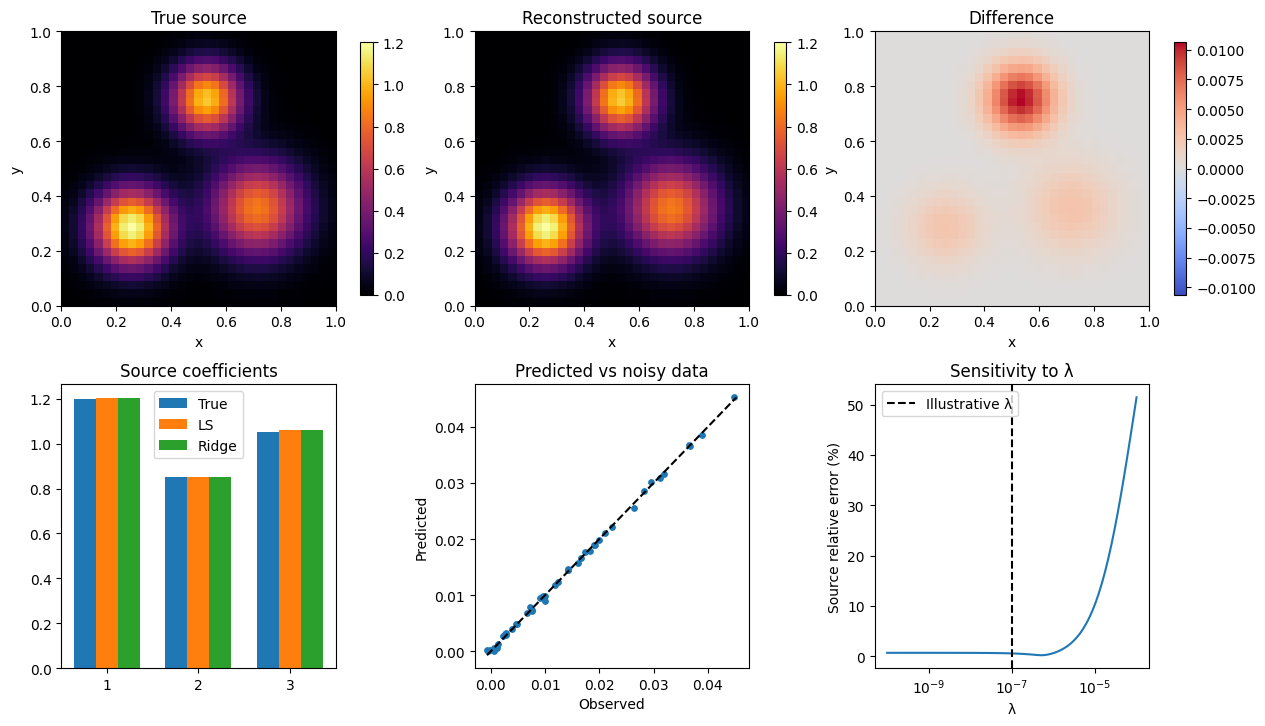

In [35]:
fig,axs=plt.subplots(2,3,figsize=(12.5,7.2),layout='constrained')
for j,(field,title) in enumerate(zip([source_true,source_ridge,source_ridge-source_true],
                                   ['True source','Reconstructed source','Difference'])):
    lim=np.max(np.abs(field)) if j==2 else np.max(source_true)
    im=axs[0,j].imshow(field.T,origin='lower',extent=[0,1,0,1],
                        cmap='coolwarm' if j==2 else 'inferno',
                        vmin=-lim if j==2 else 0,vmax=lim)
    axs[0,j].set_title(title);axs[0,j].set_xlabel('x');axs[0,j].set_ylabel('y')
    fig.colorbar(im,ax=axs[0,j],fraction=.046)
w=.24; inds=np.arange(1,p+1)
for shift,theta,label in [(-w,theta_true,'True'),(0,theta_ls,'LS'),(w,theta_ridge,'Ridge')]:
    axs[1,0].bar(inds+shift,theta,width=w,label=label)
axs[1,0].set_xticks(inds);axs[1,0].set_title('Source coefficients');axs[1,0].legend()
axs[1,1].scatter(d,A@theta_ridge,s=15)
lo,hi=min(d.min(),(A@theta_ridge).min()),max(d.max(),(A@theta_ridge).max())
axs[1,1].plot([lo,hi],[lo,hi],'k--');axs[1,1].set_title('Predicted vs noisy data')
axs[1,1].set_xlabel('Observed');axs[1,1].set_ylabel('Predicted')
lambdas=np.logspace(-10,-4,80)
source_errors=[relative_error(source_from_theta(reconstruct(A,d,L),basis),source_true) for L in lambdas]
axs[1,2].semilogx(lambdas,100*np.array(source_errors))
axs[1,2].axvline(lam,color='black',linestyle='--',label='Illustrative λ')
axs[1,2].set_title('Sensitivity to λ');axs[1,2].set_xlabel('λ')
axs[1,2].set_ylabel('Source relative error (%)');axs[1,2].legend()
plt.show()

## 7. Regularization caution and next experiments
In this particular 3-parameter, well-conditioned test, **regularization is not necessary for numerical solvability**. Small regularization may help counter noise, but larger values shrink the estimated coefficients and bias the result. The plotted true-source error is an evaluation diagnostic, not a valid data-only hyperparameter selection rule. In Task 5 we will vary noise levels, observation density, and use principled selection (e.g., validation measurements or discrepancy principle).

In [36]:
np.savez('phase4_reconstruction_results.npz',
         theta_ls=theta_ls, theta_ridge=theta_ridge, theta_true=theta_true,
         lambda_ridge=lam, source_reconstructed=source_ridge,
         source_true=source_true, d_predicted=A@theta_ridge)
print('Saved phase4_reconstruction_results.npz')

Saved phase4_reconstruction_results.npz
